
# Smart Manufacturing Machine Failure Prediction

## Objective
Build a machine learning model that estimates the probability of machine failure from operating conditions.

## Dataset
AI4I 2020 Predictive Maintenance Dataset.

## Target
`Machine failure` — binary classification.

## Key Techniques
- Exploratory Data Analysis
- Data preprocessing and pipelines
- XGBoost and model comparison
- Hyperparameter tuning with cross-validation
- Feature engineering
- Imbalanced classification
- SHAP explainability
- Precision, recall, F1-score and Average Precision
- Model persistence using joblib

## Engineered Feature
Temperature difference = Process temperature - Air temperature.


In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

In [2]:
df = pd.read_csv('../dataset.csv')
df.head(5)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.shape
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [4]:
df.isnull().sum()

UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [7]:
df["Machine failure"].value_counts(normalize=True)*100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

In [8]:
print(df.select_dtypes(include="str").nunique())
print(df.select_dtypes(include = np.number).head())

Product ID    10000
Type              3
dtype: int64
   UDI  Air temperature [K]  Process temperature [K]  Rotational speed [rpm]  \
0    1                298.1                    308.6                    1551   
1    2                298.2                    308.7                    1408   
2    3                298.1                    308.5                    1498   
3    4                298.2                    308.6                    1433   
4    5                298.2                    308.7                    1408   

   Torque [Nm]  Tool wear [min]  Machine failure  TWF  HDF  PWF  OSF  RNF  
0         42.8                0                0    0    0    0    0    0  
1         46.3                3                0    0    0    0    0    0  
2         49.4                5                0    0    0    0    0    0  
3         39.5                7                0    0    0    0    0    0  
4         40.0                9                0    0    0    0    0    0  


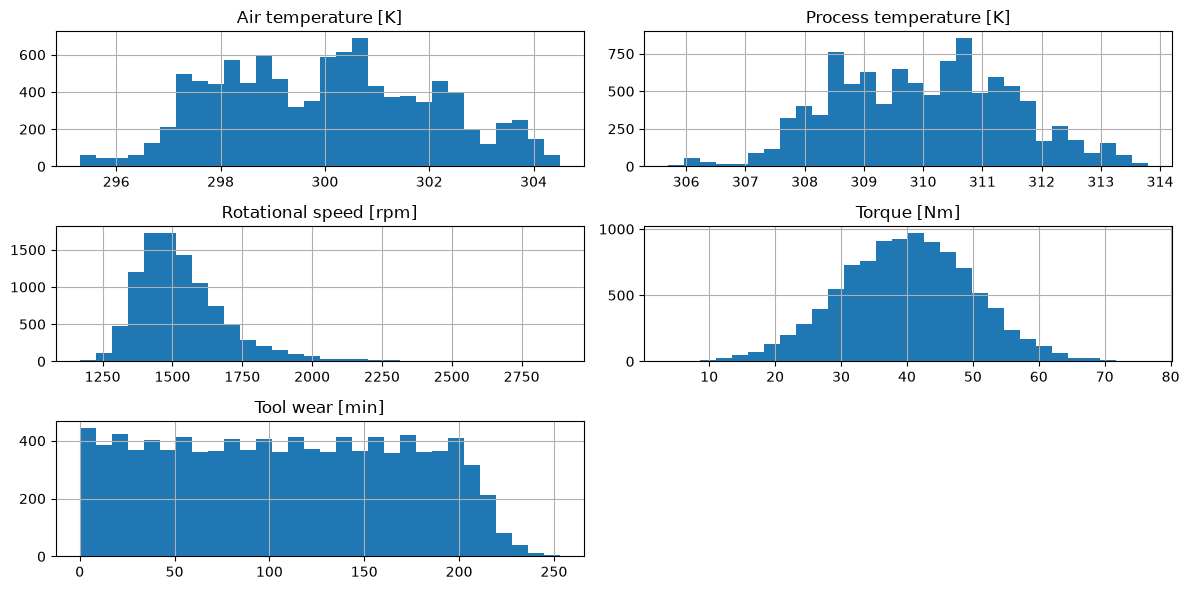

In [9]:
import seaborn as sns
numerical_cols = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]
df[numerical_cols].hist(figsize=(12,6), bins=30)
plt.tight_layout()
plt.show()

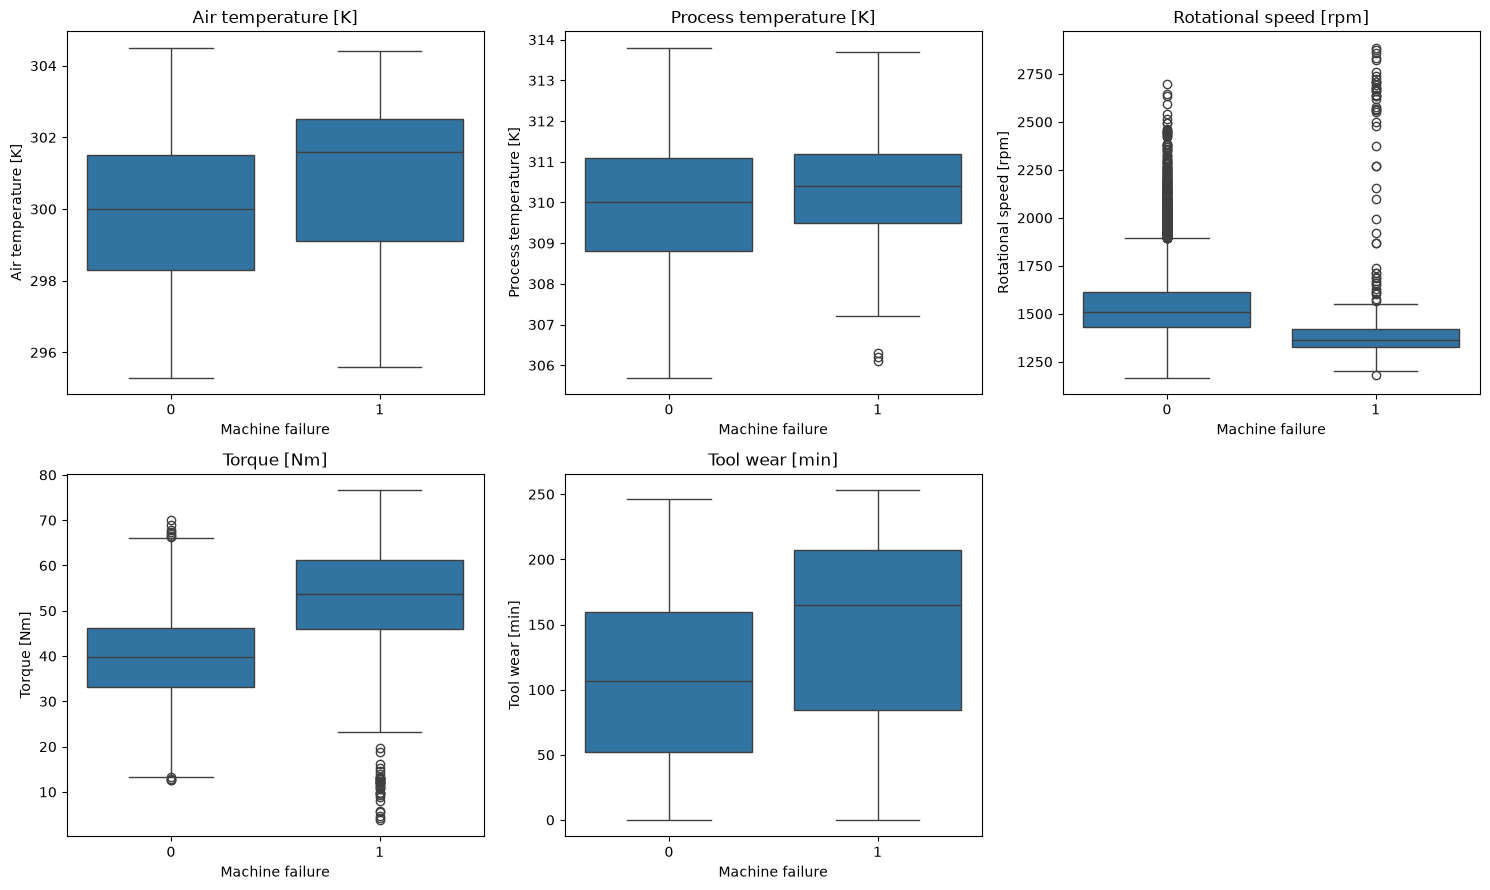

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col, ax in zip(numerical_cols, axes.flatten()):
    sns.boxplot(
        data=df,
        x="Machine failure",
        y=col,
        ax=ax
    )
    ax.set_title(col)

axes.flatten()[-1].set_visible(False)
plt.tight_layout()
plt.show()

In [11]:
failure_rate = (
    df.groupby("Type")["Machine failure"]
    .mean()
)*100
failure_rate


Type
H    2.093719
L    3.916667
M    2.769436
Name: Machine failure, dtype: float64

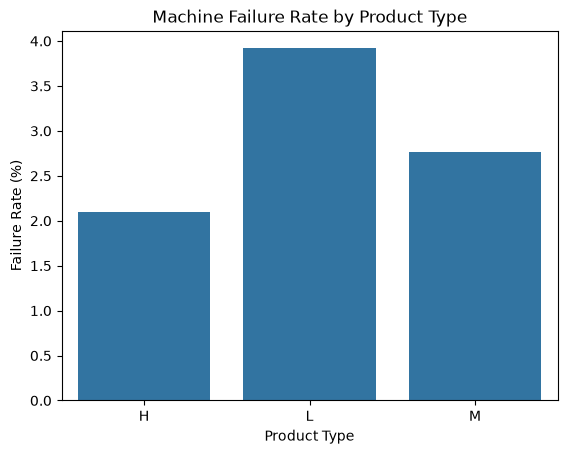

In [12]:
sns.barplot(
    x=failure_rate.index,
    y=failure_rate.values
)
plt.title("Machine Failure Rate by Product Type")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")
plt.show()

In [13]:
failure_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]
print(df[failure_cols + ["Machine failure"]].sum())

TWF                 46
HDF                115
PWF                 95
OSF                 98
RNF                 19
Machine failure    339
dtype: int64


In [14]:
print(
    pd.crosstab(
        df["Machine failure"],
        df[failure_cols].any(axis = 1),
        rownames=["Machine failure"],
        colnames=["Any failure-mode flag"]
    )
)

Any failure-mode flag  False  True 
Machine failure                    
0                       9643     18
1                          9    330


In [15]:
feature_cols = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

x = df[feature_cols]
y = df["Machine failure"]

In [16]:
y.shape

(10000,)

In [17]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test =  train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)


In [18]:
y_test.value_counts(normalize=True)*100

Machine failure
0    96.6
1     3.4
Name: proportion, dtype: float64

In [19]:
#pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer


In [20]:
df.select_dtypes(include=np.number).head()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [21]:
categorical_features = ["Type"]
numerical_features = ['Air temperature [K]','Process temperature [K]','Rotational speed [rpm]','Torque [Nm]','Tool wear [min]']

In [22]:
num_pipeline = Pipeline([
    ("imputer" , SimpleImputer(strategy = 'median')),
    ("scaler" , StandardScaler())
])
cat_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy= 'most_frequent')),
    ("encoding",OneHotEncoder(handle_unknown = 'ignore'))
])


In [23]:
preprocessor = ColumnTransformer([("num",num_pipeline,numerical_features),("cat",cat_pipeline,categorical_features)])

In [24]:
x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

print("Training:", x_train_processed.shape)
print("Testing:", x_test_processed.shape)


Training: (8000, 8)
Testing: (2000, 8)


In [25]:
%pip install xgboost


Note: you may need to restart the kernel to use updated packages.


In [26]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

import pandas as pd
def evaluate_models(x_train, x_test, y_train, y_test, preprocessor):

    models = {
        "Logistic Regression": LogisticRegression(max_iter=1000),
        "Decision Tree": DecisionTreeClassifier(random_state=42),
        "Random Forest": RandomForestClassifier(
            n_estimators=100, random_state=42
        ),
        "XGBoost": XGBClassifier(
            n_estimators=100,
            eval_metric="logloss",
            random_state=42
        )
    }
    results = []
    for name, classifier in models.items():
        model = Pipeline([
            ("preprocessor", clone(preprocessor)),
            ("classifier", classifier)
        ])
        model.fit(x_train, y_train)
        predictions = model.predict(x_test)
        probabilities = model.predict_proba(x_test)[:, 1]
        results.append({
            "Model": name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1 Score": f1_score(
                y_test, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_test, probabilities)
        })

    return pd.DataFrame(results).sort_values(
        by="F1 Score", ascending=False
    ).reset_index(drop=True)

In [27]:
results = evaluate_models(
    x_train, x_test, y_train, y_test, preprocessor
)

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,XGBoost,0.9880,0.9074,0.7206,0.8033,0.9692
1,Decision Tree,0.9785,0.6866,0.6765,0.6815,0.8328
2,Random Forest,0.9805,0.8919,0.4853,0.6286,0.9653
3,Logistic Regression,0.9675,0.6364,0.1029,0.1772,0.8994


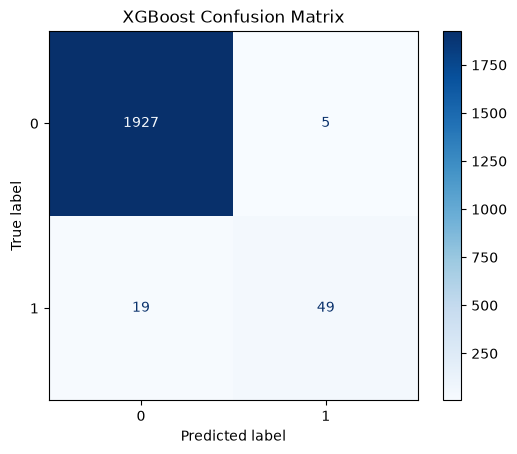

In [28]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Refit the best candidate so we have its pipeline available


best_model = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        n_estimators=100,
        eval_metric="logloss",
        random_state=42
    ))
])

best_model.fit(x_train, y_train)

y_pred = best_model.predict(x_test)

ConfusionMatrixDisplay.from_estimator(
    best_model, x_test, y_test,
    cmap="Blues"
)

plt.title("XGBoost Confusion Matrix")
plt.show()

In [29]:
from sklearn.model_selection import GridSearchCV
pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("classifier", XGBClassifier(
        eval_metric="logloss",
        random_state=42
    ))
])


In [30]:
param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 5],
    "classifier__learning_rate": [0.05, 0.1]
}

In [31]:
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    scoring="average_precision",
    cv=5,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(x_train, y_train)

Fitting 5 folds for each of 8 candidates, totalling 40 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__learning_rate': [0.05, 0.1], 'classifier__max_depth': [3, 5], 'classifier__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_au

In [32]:
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation score:")
print(grid_search.best_score_)

best_model = grid_search.best_estimator_

Best parameters:
{'classifier__learning_rate': 0.1, 'classifier__max_depth': 5, 'classifier__n_estimators': 100}

Best cross-validation score:
0.8136206077524439


In [33]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import average_precision_score

y_pred = best_model.predict(x_test)
y_prob = best_model.predict_proba(x_test)[:, 1]

print(classification_report(y_test, y_pred, zero_division=0))
print("Test Average Precision:", average_precision_score(y_test, y_prob))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.90      0.69      0.78        68

    accuracy                           0.99      2000
   macro avg       0.95      0.84      0.89      2000
weighted avg       0.99      0.99      0.99      2000

Test Average Precision: 0.8387558151703803
Confusion Matrix:
 [[1927    5]
 [  21   47]]


In [34]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

y_prob = best_model.predict_proba(x_test)[:, 1]

thresholds = np.arange(0.1, 0.91, 0.1)

results = []

for threshold in thresholds:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred_threshold, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred_threshold, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)
display(threshold_results.round(4))

,Threshold,Precision,Recall,F1 Score
0,0.1,0.5283,0.8235,0.6437
1,0.2,0.6585,0.7941,0.7200
2,0.3,0.7910,0.7794,0.7852
3,0.4,0.8772,0.7353,0.8000
4,0.5,0.9038,0.6912,0.7833
5,0.6,0.9388,0.6765,0.7863
6,0.7,0.9545,0.6176,0.7500
7,0.8,1.0000,0.4412,0.6122
8,0.9,1.0000,0.1912,0.3210


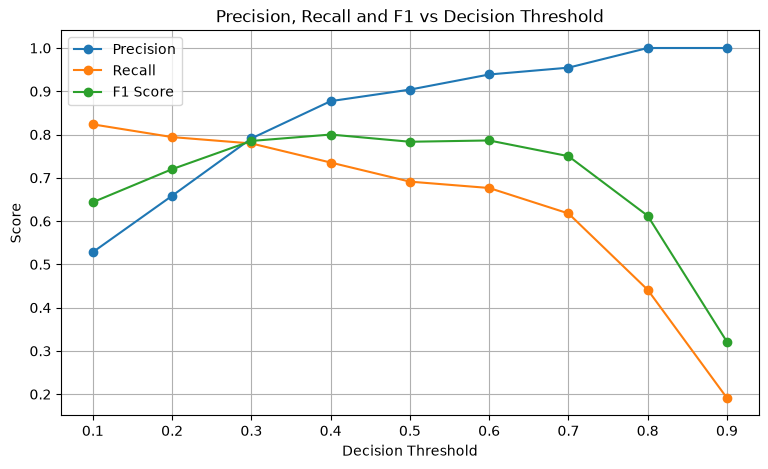

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_results["Threshold"],
    threshold_results["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Decision Threshold")
plt.legend()
plt.grid(True)
plt.show()

In [36]:
best_threshold = 0.4

y_prob = best_model.predict_proba(x_test)[:, 1]
y_pred_tuned = (y_prob >= best_threshold).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(
    y_test, y_pred_tuned, zero_division=0
))

print(confusion_matrix(y_test, y_pred_tuned))
   

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.88      0.74      0.80        68

    accuracy                           0.99      2000
   macro avg       0.93      0.87      0.90      2000
weighted avg       0.99      0.99      0.99      2000

[[1925    7]
 [  18   50]]


In [37]:

import shap
from scipy.sparse import issparse

# Extract the fitted preprocessing step and XGBoost classifier
preprocessor = best_model.named_steps["preprocessor"]
xgb_model = best_model.named_steps["classifier"]

print("Model:", type(xgb_model).__name__)
print("Preprocessor:", type(preprocessor).__name__)


Model: XGBClassifier
Preprocessor: ColumnTransformer


In [38]:

# Transform the test data using the already-fitted preprocessor
x_test_transformed = preprocessor.transform(x_test)

# Convert sparse output to a regular array if necessary
if issparse(x_test_transformed):
    x_test_transformed = x_test_transformed.toarray()

# Get the transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Create a readable DataFrame
x_test_shap = pd.DataFrame(
    x_test_transformed,
    columns=feature_names,
    index=x_test.index
)

print("Transformed shape:", x_test_shap.shape)
print("Features:", list(x_test_shap.columns))


Transformed shape: (2000, 8)
Features: ['num__Air temperature [K]', 'num__Process temperature [K]', 'num__Rotational speed [rpm]', 'num__Torque [Nm]', 'num__Tool wear [min]', 'cat__Type_H', 'cat__Type_L', 'cat__Type_M']


In [39]:

# Create a sample for SHAP
x_sample = x_test_shap.sample(
    n=min(300, len(x_test_shap)),
    random_state=42
)

# Fix feature names for XGBoost
x_sample_fixed = x_sample.copy()
x_sample_fixed.columns = (
    x_sample_fixed.columns
    .str.replace("[", "(", regex=False)
    .str.replace("]", ")", regex=False)
    .str.replace("<", "less_than", regex=False)
)

# Calculate SHAP values
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(x_sample_fixed)

print("SHAP calculation successful!")


SHAP calculation successful!


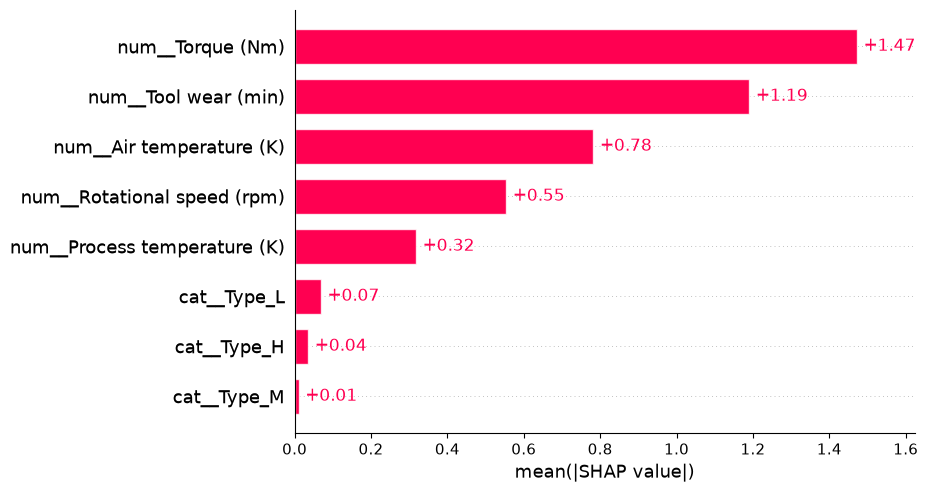

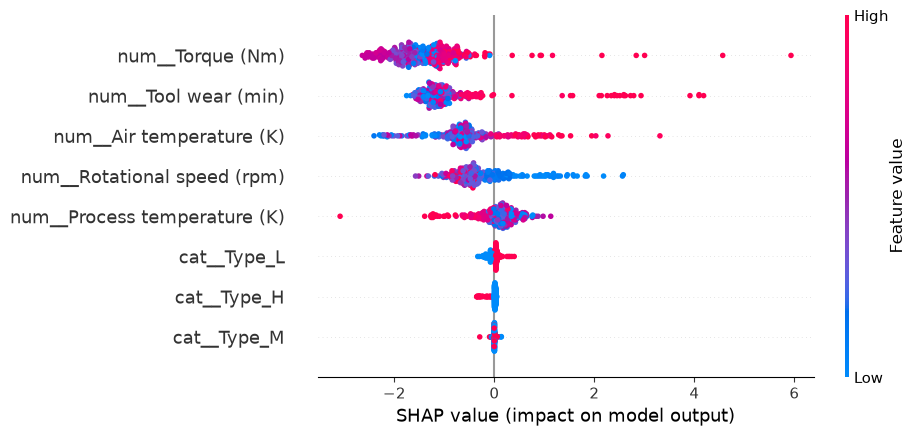

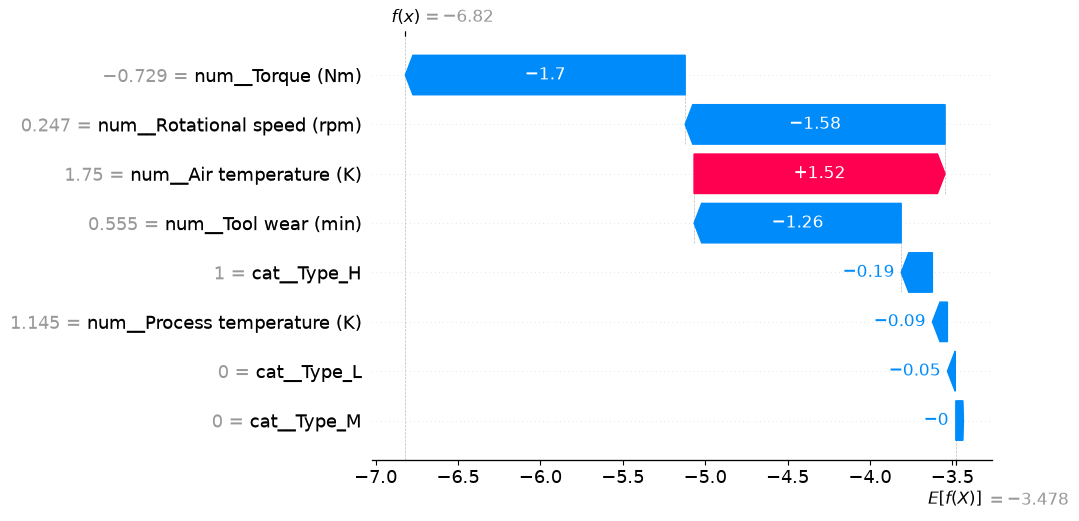

In [40]:

# Overall feature importance
shap.plots.bar(shap_values)

# How features influence predictions
shap.plots.beeswarm(shap_values)


# Select the first record from our SHAP sample
shap.plots.waterfall(shap_values[0])



In [41]:
# Get the original record corresponding to the explanation
record_index = x_sample.index[0]
machine = x_test.loc[[record_index]]

failure_probability = best_model.predict_proba(machine)[0, 1]
predicted_class = int(failure_probability >= 0.4)

print("Failure probability:", round(failure_probability, 4))
print("Predicted class:", predicted_class)
print("Actual class:", int(y_test.loc[record_index]))

Failure probability: 0.0011
Predicted class: 0
Actual class: 0


              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1932
     Failure       0.88      0.74      0.80        68

    accuracy                           0.99      2000
   macro avg       0.93      0.87      0.90      2000
weighted avg       0.99      0.99      0.99      2000



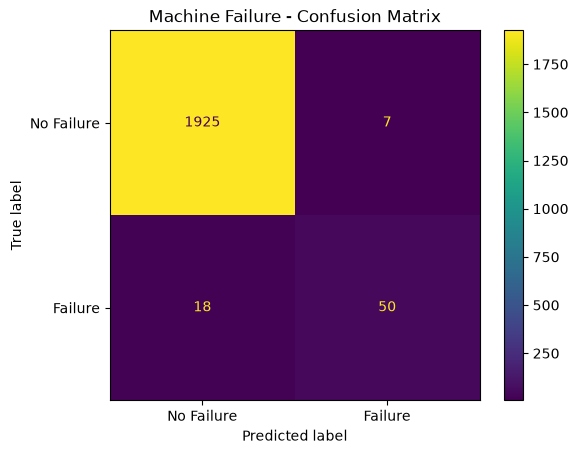

Average Precision: 0.8388


In [42]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    average_precision_score,
    precision_recall_curve
)
import matplotlib.pyplot as plt

# Predict failure probabilities
y_prob = best_model.predict_proba(x_test)[:, 1]

# Apply our provisional threshold
threshold = 0.4
y_pred = (y_prob >= threshold).astype(int)

# Print classification metrics
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
)

display.plot()
plt.title("Machine Failure - Confusion Matrix")
plt.show()

# Average Precision
ap = average_precision_score(y_test, y_prob)
print("Average Precision:", round(ap, 4))


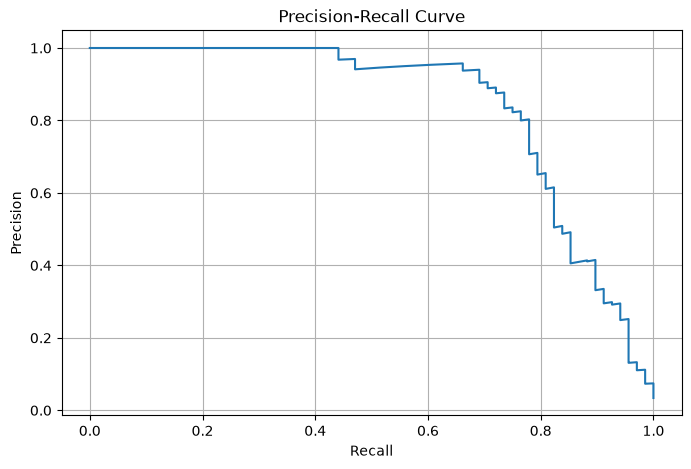

In [43]:

precision, recall, thresholds = precision_recall_curve(
    y_test, y_prob
)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.grid(True)
plt.show()


In [44]:

# Create a copy so the original dataset remains unchanged
df_engineered = df.copy()

# Difference between process temperature and air temperature
df_engineered["Temperature difference [K]"] = (
    df_engineered["Process temperature [K]"]
    - df_engineered["Air temperature [K]"]
)

print(
    df_engineered[
        ["Air temperature [K]",
         "Process temperature [K]",
         "Temperature difference [K]"]
    ].head()
)


   Air temperature [K]  Process temperature [K]  Temperature difference [K]
0                298.1                    308.6                        10.5
1                298.2                    308.7                        10.5
2                298.1                    308.5                        10.4
3                298.2                    308.6                        10.4
4                298.2                    308.7                        10.5


In [45]:

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
import pandas as pd

# Add the new feature to Xi88
x_engineered = x.copy()

x_engineered["Temperature difference [K]"] = (
    x_engineered["Process temperature [K]"]
    - x_engineered["Air temperature [K]"]
)

# Use the same train/test row split as before
x_train_eng = x_engineered.loc[x_train.index]

# Create the baseline and engineered feature sets
x_train_base = x.loc[x_train.index]

# Cross-validation setup
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

def evaluate_cv(x_data, preprocessor):
    model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            n_estimators=100,
            max_depth=3,
            learning_rate=0.1,
            eval_metric="logloss",
            random_state=42
        ))
    ])

    scores = cross_val_score(
        model,
        x_data,
        y_train,
        cv=cv,
        scoring="average_precision",
        n_jobs=-1
    )

    return scores

# Baseline: original features
baseline_scores = evaluate_cv(x_train_base, preprocessor)

# Engineered: add temperature difference
preprocessor_eng = clone(preprocessor)
preprocessor_eng.transformers = [
    ("num", num_pipeline, numerical_features + ["Temperature difference [K]"]),
    ("cat", cat_pipeline, categorical_features)
]

engineered_scores = evaluate_cv(x_train_eng, preprocessor_eng)

print("Baseline AP:", round(baseline_scores.mean(), 4))
print("Engineered AP:", round(engineered_scores.mean(), 4))
print("Baseline fold scores:", baseline_scores.round(4))
print("Engineered fold scores:", engineered_scores.round(4))


Baseline AP: 0.7546
Engineered AP: 0.8161
Baseline fold scores: [0.8331 0.7546 0.7305 0.7117 0.7431]
Engineered fold scores: [0.8855 0.8026 0.8068 0.7745 0.8109]


In [46]:

# Feature lists for the engineered model
numerical_features_eng = numerical_features + [
    "Temperature difference [K]"
]

categorical_features_eng = categorical_features.copy()

numeric_pipeline_eng = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline_eng = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_eng = ColumnTransformer([
    ("num", numeric_pipeline_eng, numerical_features_eng),
    ("cat", categorical_pipeline_eng, categorical_features_eng)
])

print("Numerical features:", numerical_features_eng)
print("Categorical features:", categorical_features_eng)


Numerical features: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature difference [K]']
Categorical features: ['Type']


In [47]:

# Add the feature to both datasets
x_train_eng = x_engineered.loc[x_train.index]
x_test_eng = x_engineered.loc[x_test.index]

print("Training shape:", x_train_eng.shape)
print("Testing shape:", x_test_eng.shape)


Training shape: (8000, 7)
Testing shape: (2000, 7)


In [48]:
pipeline_eng = Pipeline([
    ("preprocessor", clone(preprocessor_eng)),
    ("classifier", XGBClassifier(
        eval_metric="logloss",
        random_state=42
    ))
])

param_grid_eng = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 5],
    "classifier__learning_rate": [0.05, 0.1]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search_eng = GridSearchCV(
    estimator=pipeline_eng,
    param_grid=param_grid_eng,
    scoring="average_precision",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search_eng.fit(x_train_eng, y_train)

best_model_eng = grid_search_eng.best_estimator_

print("Best parameters:", grid_search_eng.best_params_)
print("Best cross-validation AP:", round(grid_search_eng.best_score_, 4))


Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best parameters: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__n_estimators': 100}
Best cross-validation AP: 0.8334


In [49]:
from xgboost import XGBClassifier

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [3, 5],
    "classifier__learning_rate": [0.05, 0.1]
}

def tune_model(X_data, preprocessor):
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("classifier", XGBClassifier(
            eval_metric="logloss",
            random_state=42
        ))
    ])

    search = GridSearchCV(
        pipeline,
        param_grid,
        scoring="average_precision",
        cv=cv,
        n_jobs=-1,
        verbose=0
    )

    search.fit(X_data, y_train)
    return search

# Tune both models using the same setup
baseline_search = tune_model(x_train_base, preprocessor)
engineered_search = tune_model(x_train_eng, preprocessor_eng)

print("Baseline AP:", round(baseline_search.best_score_, 4))
print("Engineered AP:", round(engineered_search.best_score_, 4))

print("\nBaseline best parameters:")
print(baseline_search.best_params_)

print("\nEngineered best parameters:")
print(engineered_search.best_params_)


Baseline AP: 0.782
Engineered AP: 0.8334

Baseline best parameters:
{'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__n_estimators': 100}

Engineered best parameters:
{'classifier__learning_rate': 0.05, 'classifier__max_depth': 5, 'classifier__n_estimators': 100}


In [50]:
# Calculate the class weight from training data only
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

weight = negative / positive

print("Negative samples:", negative)
print("Positive samples:", positive)
print("scale_pos_weight:", round(weight, 2))

# Train a weighted XGBoost model
weighted_model = Pipeline([
    ("preprocessor", clone(preprocessor_eng)),
    ("classifier", XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        scale_pos_weight=weight,
        eval_metric="logloss",
        random_state=42
    ))
])

# Evaluate using 5-fold cross-validation
scores = cross_val_score(
    weighted_model,
    x_train_eng,
    y_train,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1
)

print("Weighted model AP:", round(scores.mean(), 4))
print("Fold scores:", scores.round(4))


Negative samples: 7729
Positive samples: 271
scale_pos_weight: 28.52
Weighted model AP: 0.7562
Fold scores: [0.8429 0.7641 0.745  0.6964 0.7329]


In [51]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Generate out-of-fold probabilities for the weighted model
y_prob_weighted = cross_val_predict(
    weighted_model,
    x_train_eng,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Use 0.5 temporarily for comparison
y_pred_weighted = (y_prob_weighted >= 0.5).astype(int)

print(classification_report(
    y_train,
    y_pred_weighted,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_train, y_pred_weighted))


              precision    recall  f1-score   support

  No Failure       1.00      0.95      0.97      7729
     Failure       0.36      0.89      0.52       271

    accuracy                           0.94      8000
   macro avg       0.68      0.92      0.74      8000
weighted avg       0.97      0.94      0.95      8000

Confusion matrix:
[[7307  422]
 [  29  242]]


In [52]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [53]:

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import cross_val_score
smote_model = ImbPipeline([
    ("preprocessor", clone(preprocessor_eng)),
    ("smote", SMOTE(random_state=42)),
    ("classifier", XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.1,
        eval_metric="logloss",
        random_state=42
    ))
])

smote_scores = cross_val_score(
    smote_model,
    x_train_eng,
    y_train,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1
)

print("SMOTE Average Precision:", round(smote_scores.mean(), 4))
print("Fold scores:", smote_scores.round(4))


SMOTE Average Precision: 0.7803
Fold scores: [0.8169 0.7727 0.78   0.7597 0.7723]


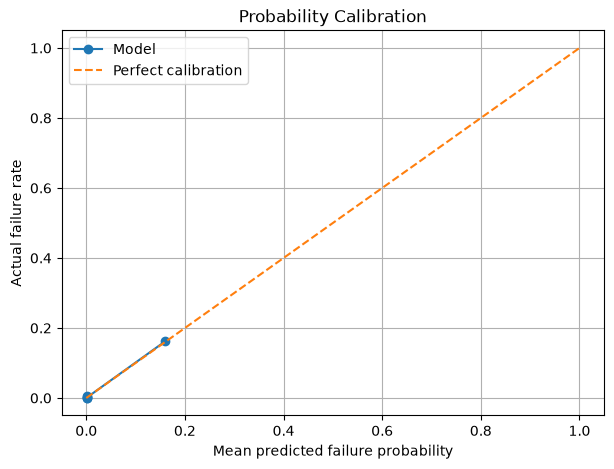

In [54]:
from sklearn.calibration import calibration_curve
y_prob = best_model_eng.predict_proba(x_test_eng)[:, 1]

# Compare predicted probabilities with observed failure rates
actual_rate, predicted_rate = calibration_curve(
    y_test,
    y_prob,
    n_bins=5,
    strategy="quantile"
)

plt.figure(figsize=(7, 5))
plt.plot(predicted_rate, actual_rate, marker="o", label="Model")
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")

plt.xlabel("Mean predicted failure probability")
plt.ylabel("Actual failure rate")
plt.title("Probability Calibration")
plt.legend()
plt.grid(True)
plt.show()


In [55]:
from sklearn.metrics import average_precision_score

# Try a simple tree and a more complex tree
models = {
    "Shallow Tree": DecisionTreeClassifier(
        max_depth=2, random_state=42
    ),
    "Deep Tree": DecisionTreeClassifier(
        max_depth=None, random_state=42
    )
}

for name, classifier in models.items():
    model = Pipeline([
        ("preprocessor", clone(preprocessor_eng)),
        ("classifier", classifier)
    ])

    model.fit(x_train_eng, y_train)

    train_prob = model.predict_proba(x_train_eng)[:, 1]
    test_prob = model.predict_proba(x_test_eng)[:, 1]

    print(name)
    print("Train AP:", round(
        average_precision_score(y_train, train_prob), 4
    ))
    print("Test AP:", round(
        average_precision_score(y_test, test_prob), 4
    ))
    print()


Shallow Tree
Train AP: 0.2521
Test AP: 0.1814

Deep Tree
Train AP: 1.0
Test AP: 0.5681



In [56]:
from sklearn.linear_model import LogisticRegression

# Stronger regularization
model_l1 = LogisticRegression(
    penalty="l1", solver="liblinear", C=0.1
)

# L2 regularization
model_l2 = LogisticRegression(
    penalty="l2", C=1.0, max_iter=1000
)

In [57]:

from sklearn.inspection import permutation_importance

# Use the trained engineered model
result = permutation_importance(
    best_model_eng,
    x_test_eng,
    y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance = pd.DataFrame({
    "Feature": x_test_eng.columns,
    "Importance": result.importances_mean
}).sort_values("Importance", ascending=False)

print(importance)


                      Feature  Importance
3      Rotational speed [rpm]    0.530243
6  Temperature difference [K]    0.484766
4                 Torque [Nm]    0.477490
5             Tool wear [min]    0.307606
0                        Type    0.033136
1         Air temperature [K]    0.001027
2     Process temperature [K]   -0.002486


In [58]:

from sklearn.model_selection import train_test_split

# Start from the original features, before adding engineered features
feature_cols = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[feature_cols]
y = df["Machine failure"]

# Fresh split: keep this test set untouched until the end
x_train_final, x_test_final, y_train_final, y_test_final = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=101,
    stratify=y
)

print("Training rows:", len(x_train_final))
print("Final test rows:", len(x_test_final))
print("Training failure rate:", round(y_train_final.mean(), 4))
print("Test failure rate:", round(y_test_final.mean(), 4))


Training rows: 8000
Final test rows: 2000
Training failure rate: 0.0339
Test failure rate: 0.034


In [59]:

# Add the same feature to training and test data
x_train_final = x_train_final.copy()
x_test_final = x_test_final.copy()

for data in [x_train_final, x_test_final]:
    data["Temperature difference [K]"] = (
        data["Process temperature [K]"]
        - data["Air temperature [K]"]
    )

print("Training shape:", x_train_final.shape)
print("Final test shape:", x_test_final.shape)


Training shape: (8000, 7)
Final test shape: (2000, 7)


In [60]:

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

final_model = Pipeline([
    ("preprocessor", clone(preprocessor_eng)),
    ("classifier", XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.05,
        eval_metric="logloss",
        random_state=42
    ))
])

final_model.fit(x_train_final, y_train_final)

print("Final model trained.")


Final model trained.


Final Average Precision: 0.8411

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1932
     Failure       0.90      0.66      0.76        68

    accuracy                           0.99      2000
   macro avg       0.94      0.83      0.88      2000
weighted avg       0.99      0.99      0.98      2000



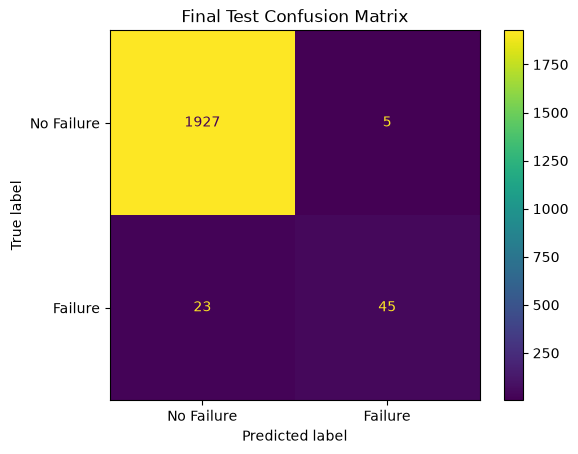

In [61]:

from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

y_prob_final = final_model.predict_proba(x_test_final)[:, 1]
y_pred_final = (y_prob_final >= 0.5).astype(int)

print("Final Average Precision:",
      round(average_precision_score(y_test_final, y_prob_final), 4))

print("\nClassification Report:")
print(classification_report(
    y_test_final,
    y_pred_final,
    target_names=["No Failure", "Failure"],
    zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test_final,
    y_pred_final,
    display_labels=["No Failure", "Failure"]
)
plt.title("Final Test Confusion Matrix")
plt.show()


In [62]:

import joblib
from pathlib import Path

# Create the models folder in the project root
Path("../models").mkdir(parents=True, exist_ok=True)

# Save the fitted model pipeline
joblib.dump(
    final_model,
    "../models/machine_failure_model.joblib"
)

print("Final model saved successfully!")


Final model saved successfully!


In [63]:
# Load the saved model from disk
loaded_model = joblib.load(
    "../models/machine_failure_model.joblib"
)

# Take one machine from the final test dataset
sample = x_test_final.iloc[[0]].copy()

# Predict failure probability
probability = loaded_model.predict_proba(sample)[0, 1]

print("Failure probability:", round(probability, 4))
print("Actual outcome:", int(y_test_final.iloc[0]))


Failure probability: 0.0821
Actual outcome: 0


In [64]:

def predict_machine_failure(model, machine_data, threshold=0.5):
    probability = model.predict_proba(machine_data)[0, 1]
    prediction = int(probability >= threshold)

    return {
        "failure_probability": round(float(probability), 4),
        "prediction": prediction,
        "result": "Failure" if prediction == 1 else "No Failure"
    }


# Test using one machine from the final test set
sample = x_test_final.iloc[[0]].copy()

result = predict_machine_failure(
    loaded_model,
    sample,
    threshold=0.5
)

print(result)


{'failure_probability': 0.0821, 'prediction': 0, 'result': 'No Failure'}


In [65]:
loaded_model = joblib.load(
    "../models/machine_failure_model.joblib"
)

print("Model loaded successfully")
print("Expected input features:")
print(list(loaded_model.feature_names_in_))


Model loaded successfully
Expected input features:
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature difference [K]']


In [66]:
# Load the model once
loaded_model = joblib.load(
    "../models/machine_failure_model.joblib"
)

# Our provisional threshold from the earlier experiment
best_threshold = 0.4

# Select five records from the final test set
samples = x_test_final.iloc[:5].copy()

# Predict failure probabilities
probabilities = loaded_model.predict_proba(samples)[:, 1]

# Apply the selected threshold
predictions = (probabilities >= best_threshold).astype(int)

# Display results
results = pd.DataFrame({
    "Failure Probability": probabilities.round(4),
    "Predicted Class": predictions,
    "Prediction": [
        "Failure" if p == 1 else "No Failure"
        for p in predictions
    ],
    "Actual Class": y_test_final.iloc[:5].values
}, index=samples.index)

print("Threshold:", best_threshold)
print(results)


Threshold: 0.4
      Failure Probability  Predicted Class  Prediction  Actual Class
4023               0.0821                0  No Failure             0
2833               0.0051                0  No Failure             0
7072               0.0026                0  No Failure             0
6097               0.0010                0  No Failure             0
9988               0.0377                0  No Failure             0


In [67]:
# Predict probabilities for the entire test set
y_prob = loaded_model.predict_proba(x_test_final)[:, 1]

# Apply threshold 0.4
best_threshold = 0.4
y_pred = (y_prob >= best_threshold).astype(int)

print("Threshold:", best_threshold)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test_final, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test_final,
    y_pred,
    target_names=["No Failure", "Failure"]
))

print(
    "Average Precision:",
    round(average_precision_score(y_test_final, y_prob), 4)
)


Threshold: 0.4

Confusion Matrix:
[[1924    8]
 [  19   49]]

Classification Report:
              precision    recall  f1-score   support

  No Failure       0.99      1.00      0.99      1932
     Failure       0.86      0.72      0.78        68

    accuracy                           0.99      2000
   macro avg       0.92      0.86      0.89      2000
weighted avg       0.99      0.99      0.99      2000

Average Precision: 0.8411


In [70]:

import joblib

MODEL_PATH = "../models/machine_failure_model.joblib"
THRESHOLD = 0.4

model = joblib.load(MODEL_PATH)

print("Model loaded successfully!")



Model loaded successfully!
